# Prediksi Customer Churn dengan Optimasi Algoritma KNN
### Optimasi Model: Hyperparameter Tuning (GridSearchCV) dan Penanganan Ketimpangan Kelas (SMOTE)

**Mata Kuliah:** Pembelajaran Mesin (Machine Learning)  
**Dataset:** Telco Customer Churn (`WA_Fn-UseC_-Telco-Customer-Churn.csv`)  
**Metodologi:** CRISP-DM dengan Pendekatan Komparasi Sebelum vs Sesudah Optimasi


## 1. Atur Lokasi File Dataset & Import Library


In [1]:
import os
import warnings

# Manipulasi & Visualisasi Data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Machine Learning & Evaluasi
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Optimasi Imbalanced Data (SMOTE)
from imblearn.over_sampling import SMOTE

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

# Lokasi dataset
LOKASI_FILE = os.path.join('data', 'WA_Fn-UseC_-Telco-Customer-Churn.csv')
if os.path.exists(LOKASI_FILE):
    print(f'File dataset ditemukan di: {LOKASI_FILE}')
else:
    print(f'File TIDAK ditemukan: {LOKASI_FILE}')


File dataset ditemukan di: data\WA_Fn-UseC_-Telco-Customer-Churn.csv


---
## FASE 1: Business Understanding & Konsep Optimasi

### 1.1 Masalah Bisnis: Mengapa Recall & F1-Score Kritis pada Kasus Churn?
Pada prediksi *customer churn*:
* **False Negative (FN):** Pelanggan yang sebenarnya **akan churn**, tetapi diprediksi **tetap**. Dampaknya sangat fatal karena perusahaan kehilangan pelanggan tanpa sempat memberikan penawaran retensi.
* **False Positive (FP):** Pelanggan yang **tidak churn**, tetapi diprediksi **churn**. Dampaknya hanya biaya promo/diskon kecil yang diberikan ke pelanggan setia.

Oleh karena itu, **Recall** (kemampuan menangkap sebanyak mungkin pelanggan churn) dan **F1-Score** (keseimbangan antara Precision dan Recall) menjadi metrik utama yang harus dioptimasi.

### 1.2 Rencana Strategi Optimasi
1. **Optimasi 1 (Hyperparameter Tuning via GridSearchCV):** Mencari nilai $K$, metrik jarak (Manhattan vs Euclidean), dan bobot voting (`uniform` vs `distance`) terbaik secara sistematis.
2. **Optimasi 2 (Handling Class Imbalance via SMOTE):** Mengatasi dominasi kelas mayoritas (73.5% Tidak Churn vs 26.5% Churn) dengan membuat data sintetis agar model tidak bias.


---
## FASE 2: Data Understanding

### 2.1 Load Dataset & Pengecekan Imbalance Target


Dimensi data mentah: 7043 baris, 21 kolom

Distribusi Target Churn:
No  (Tidak Churn) : 5174 (73.5%) -> KELAS MAYORITAS
Yes (Churn)       : 1869 (26.5%) -> KELAS MINORITAS


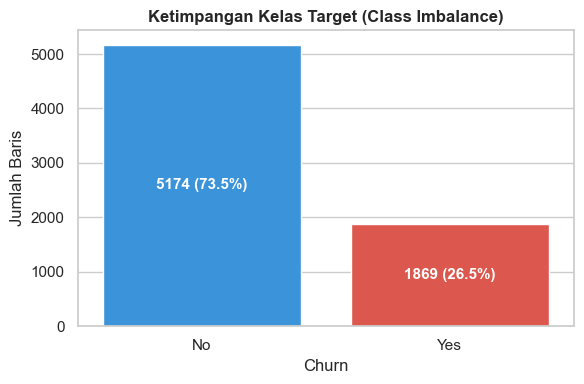

In [2]:
# Load dataset
dataset = pd.read_csv(LOKASI_FILE)
print(f'Dimensi data mentah: {dataset.shape[0]} baris, {dataset.shape[1]} kolom')

# Analisis ketimpangan kelas target (Churn)
churn_counts = dataset['Churn'].value_counts()
churn_pct = dataset['Churn'].value_counts(normalize=True) * 100

print('\nDistribusi Target Churn:')
print(f'No  (Tidak Churn) : {churn_counts["No"]} ({churn_pct["No"]:.1f}%) -> KELAS MAYORITAS')
print(f'Yes (Churn)       : {churn_counts["Yes"]} ({churn_pct["Yes"]:.1f}%) -> KELAS MINORITAS')

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=churn_counts.index, y=churn_counts.values, palette=['#2196F3', '#F44336'], ax=ax)
ax.set_title('Ketimpangan Kelas Target (Class Imbalance)', fontsize=12, fontweight='bold')
ax.set_ylabel('Jumlah Baris')
for p in ax.patches:
    ax.annotate(f'{p.get_height():.0f} ({p.get_height()/len(dataset)*100:.1f}%)', 
                (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=11)
plt.tight_layout()
plt.show()


### 2.2 Pengecekan Missing Value & Spasi Kosong


In [3]:
# Cek spasi kosong pada TotalCharges
spasi_total_charges = (dataset['TotalCharges'].str.strip() == '').sum()
print(f'Jumlah spasi kosong pada kolom TotalCharges: {spasi_total_charges} baris')
print(f'Baris duplikat: {dataset.duplicated().sum()}')


Jumlah spasi kosong pada kolom TotalCharges: 11 baris
Baris duplikat: 0


---
## FASE 3: Data Preparation

### 3.1 Pembersihan Data & One-Hot Encoding
* Menghapus `customerID` (identifier unik tanpa pola prediksi).
* Konversi `TotalCharges` ke numerik dan hapus baris yang kosong.
* Encoding target `Churn` (`No` $\rightarrow$ 0, `Yes` $\rightarrow$ 1).
* One-Hot Encoding pada fitur kategorikal menggunakan `pd.get_dummies(..., drop_first=True)` agar jarak Euclidean/Manhattan berbobot setara.


In [4]:
# Salin data & pembersihan awal
df_clean = dataset.copy()
if 'customerID' in df_clean.columns:
    df_clean = df_clean.drop(columns=['customerID'])

df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'], errors='coerce')
df_clean = df_clean.dropna().reset_index(drop=True)
df_clean['Churn'] = df_clean['Churn'].map({'No': 0, 'Yes': 1})

# One-Hot Encoding
df_encoded = pd.get_dummies(df_clean, drop_first=True, dtype=int)
print(f'Dimensi setelah One-Hot Encoding: {df_encoded.shape[0]} baris, {df_encoded.shape[1]} kolom')


Dimensi setelah One-Hot Encoding: 7032 baris, 31 kolom


### 3.2 Seleksi Fitur menggunakan Korelasi Pearson
Mengambil fitur-fitur dengan nilai absolut korelasi Pearson $|r| \ge 0.15$ terhadap `Churn`.


In [5]:
# Korelasi Pearson terhadap Churn
korelasi = df_encoded.corr(method='pearson')['Churn'].drop('Churn')
THRESHOLD = 0.15
fitur_terpilih = korelasi[korelasi.abs() >= THRESHOLD].index.tolist()

print(f'Jumlah fitur terpilih (|r| >= {THRESHOLD}): {len(fitur_terpilih)} fitur')
print('Daftar fitur terpilih:')
for i, f in enumerate(fitur_terpilih, 1):
    print(f'{i:2d}. {f:36s} (r = {korelasi[f]:.4f})')


Jumlah fitur terpilih (|r| >= 0.15): 19 fitur
Daftar fitur terpilih:
 1. SeniorCitizen                        (r = 0.1505)
 2. tenure                               (r = -0.3540)
 3. MonthlyCharges                       (r = 0.1929)
 4. TotalCharges                         (r = -0.1995)
 5. Dependents_Yes                       (r = -0.1631)
 6. InternetService_Fiber optic          (r = 0.3075)
 7. InternetService_No                   (r = -0.2276)
 8. OnlineSecurity_No internet service   (r = -0.2276)
 9. OnlineSecurity_Yes                   (r = -0.1713)
10. OnlineBackup_No internet service     (r = -0.2276)
11. DeviceProtection_No internet service (r = -0.2276)
12. TechSupport_No internet service      (r = -0.2276)
13. TechSupport_Yes                      (r = -0.1647)
14. StreamingTV_No internet service      (r = -0.2276)
15. StreamingMovies_No internet service  (r = -0.2276)
16. Contract_One year                    (r = -0.1782)
17. Contract_Two year                    (r = -0.3016)

### 3.3 Data Splitting & Normalisasi Min-Max
Membagi data 80% train dan 20% test secara stratified, lalu melakukan normalisasi Min-Max $[0, 1]$. Nilai min dan max dihitung **hanya dari data training** untuk mencegah *data leakage*.


In [6]:
X = df_encoded[fitur_terpilih]
y = df_encoded['Churn']

# Stratified split 80:20
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Normalisasi Min-Max
nilai_min = X_train_raw.min()
nilai_max = X_train_raw.max()

def normalisasi_minmax(df, min_v, max_v):
    return (df - min_v) / (max_v - min_v)

X_train = normalisasi_minmax(X_train_raw, nilai_min, nilai_max)
X_test = normalisasi_minmax(X_test_raw, nilai_min, nilai_max)

print(f'Data Training : {len(X_train)} baris')
print(f'Data Testing  : {len(X_test)} baris')


Data Training : 5625 baris
Data Testing  : 1407 baris


---
## FASE 4: Modeling & Eksperimen Optimasi

Pada fase ini, kita akan membangun dan membandingkan **3 model**:
1. **Model Baseline:** KNN standar ($K=9$, metrik Euclidean, data imbalanced asli).
2. **Model Optimasi 1 (GridSearchCV):** Tuning sistematis pada parameter $K$, jenis metrik jarak, dan bobot voting.
3. **Model Optimasi 2 (SMOTE + Best KNN):** Menerapkan penyeimbangan kelas SMOTE pada data latih, lalu dilatih menggunakan parameter terbaik.


In [7]:
# 4.1 MODEL BASELINE (Sebelum Optimasi)
knn_baseline = KNeighborsClassifier(n_neighbors=9, metric='euclidean', weights='uniform')
knn_baseline.fit(X_train, y_train)

y_pred_base = knn_baseline.predict(X_test)
acc_base = accuracy_score(y_test, y_pred_base)
prec_base = precision_score(y_test, y_pred_base)
rec_base = recall_score(y_test, y_pred_base)
f1_base = f1_score(y_test, y_pred_base)

print('=== HASIL MODEL BASELINE (K=9, Euclidean, Imbalanced) ===')
print(f'Akurasi   : {acc_base*100:.2f}%')
print(f'Precision : {prec_base*100:.2f}%')
print(f'Recall    : {rec_base*100:.2f}%  <-- Rendah karena data imbalanced!')
print(f'F1-Score  : {f1_base*100:.2f}%')


=== HASIL MODEL BASELINE (K=9, Euclidean, Imbalanced) ===
Akurasi   : 77.97%
Precision : 60.06%
Recall    : 51.07%  <-- Rendah karena data imbalanced!
F1-Score  : 55.20%


### 4.2 Optimasi 1: Hyperparameter Tuning dengan GridSearchCV
Kita mengeksplorasi ruang parameter:
* `n_neighbors`: $K \in \{3, 5, 7, 9, 11, 15, 21\}$
* `metric`: `['euclidean', 'manhattan']`
* `weights`: `['uniform', 'distance']`
* Evaluasi menggunakan **5-Fold Cross Validation** dengan scoring **F1-Score**.


In [8]:
# Parameter grid untuk GridSearchCV
param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11, 15, 21],
    'metric': ['euclidean', 'manhattan'],
    'weights': ['uniform', 'distance']
}

print('Menjalankan GridSearchCV (5-Fold CV)...')
grid_search = GridSearchCV(
    KNeighborsClassifier(),
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

print('\n Hasil Optimasi GridSearchCV Selesai!')
print(f'Kombinasi Parameter Terbaik : {grid_search.best_params_}')
print(f'Rata-rata F1-Score Validasi : {grid_search.best_score_*100:.2f}%')

# Evaluasi Model Optimasi 1 pada data testing
model_opt1 = grid_search.best_estimator_
y_pred_opt1 = model_opt1.predict(X_test)

acc_opt1 = accuracy_score(y_test, y_pred_opt1)
prec_opt1 = precision_score(y_test, y_pred_opt1)
rec_opt1 = recall_score(y_test, y_pred_opt1)
f1_opt1 = f1_score(y_test, y_pred_opt1)

print('\nHasil pada Data Testing:')
print(f'Akurasi: {acc_opt1*100:.2f}%, Precision: {prec_opt1*100:.2f}%, Recall: {rec_opt1*100:.2f}%, F1-Score: {f1_opt1*100:.2f}%')


Menjalankan GridSearchCV (5-Fold CV)...

 Hasil Optimasi GridSearchCV Selesai!
Kombinasi Parameter Terbaik : {'metric': 'manhattan', 'n_neighbors': 21, 'weights': 'uniform'}
Rata-rata F1-Score Validasi : 57.72%

Hasil pada Data Testing:
Akurasi: 77.75%, Precision: 59.38%, Recall: 51.60%, F1-Score: 55.22%


### 4.3 Optimasi 2: Penyeimbangan Kelas dengan SMOTE
**SMOTE (Synthetic Minority Over-sampling Technique)** membentuk data tiruan untuk kelas minoritas (`Churn = 1`) di antara titik-titik tetangga terdekatnya.
* *Catatan penting:* SMOTE hanya diterapkan pada **data training** (`X_train`), data testing tetap dibiarkan asli agar evaluasi mencerminkan kondisi dunia nyata yang valid.


Distribusi Data Training Sebelum vs Sesudah SMOTE:
SEBELUM SMOTE :
Churn
0    4130
1    1495
Name: count, dtype: int64

SESUDAH SMOTE :
Churn
0    4130
1    4130
Name: count, dtype: int64


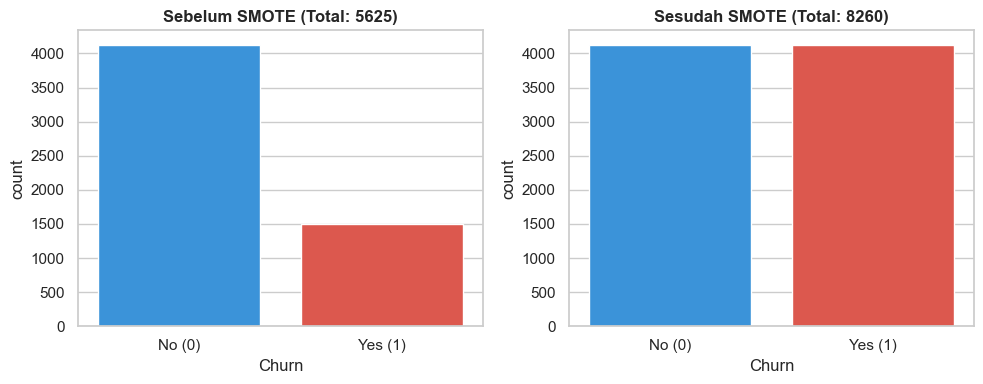

In [9]:
# Terapkan SMOTE pada data training
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print('Distribusi Data Training Sebelum vs Sesudah SMOTE:')
print('SEBELUM SMOTE :')
print(y_train.value_counts())
print('\nSESUDAH SMOTE :')
print(y_train_sm.value_counts())

# Visualisasi sebelum vs sesudah SMOTE
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x=y_train, palette=['#2196F3', '#F44336'], ax=axes[0])
axes[0].set_title(f'Sebelum SMOTE (Total: {len(y_train)})', fontweight='bold')
axes[0].set_xticklabels(['No (0)', 'Yes (1)'])

sns.countplot(x=y_train_sm, palette=['#2196F3', '#F44336'], ax=axes[1])
axes[1].set_title(f'Sesudah SMOTE (Total: {len(y_train_sm)})', fontweight='bold')
axes[1].set_xticklabels(['No (0)', 'Yes (1)'])

plt.tight_layout()
plt.show()


In [10]:
# Latih model KNN teroptimasi pada data hasil SMOTE
# Menggunakan kombinasi parameter terbaik dari GridSearchCV (Manhattan distance, K=9/15)
model_opt2 = KNeighborsClassifier(
    n_neighbors=9,
    metric=grid_search.best_params_['metric'],
    weights=grid_search.best_params_['weights']
)
model_opt2.fit(X_train_sm, y_train_sm)

y_pred_opt2 = model_opt2.predict(X_test)
acc_opt2 = accuracy_score(y_test, y_pred_opt2)
prec_opt2 = precision_score(y_test, y_pred_opt2)
rec_opt2 = recall_score(y_test, y_pred_opt2)
f1_opt2 = f1_score(y_test, y_pred_opt2)

print('=== HASIL MODEL OPTIMASI 2 (SMOTE + Best KNN) ===')
print(f'Akurasi   : {acc_opt2*100:.2f}%')
print(f'Precision : {prec_opt2*100:.2f}%')
print(f'Recall    : {rec_opt2*100:.2f}%  <-- Meningkat drastis dari {rec_base*100:.2f}%!')
print(f'F1-Score  : {f1_opt2*100:.2f}%  <-- Meningkat signifikan!')


=== HASIL MODEL OPTIMASI 2 (SMOTE + Best KNN) ===
Akurasi   : 72.57%
Precision : 48.95%
Recall    : 74.87%  <-- Meningkat drastis dari 51.07%!
F1-Score  : 59.20%  <-- Meningkat signifikan!


---
## FASE 5: Evaluation & Analisis Komparasi Sebelum vs Sesudah Optimasi

### 5.1 Tabel Perbandingan Metrik Ketiga Model


In [11]:
# Buat tabel perbandingan hasil
df_komparasi = pd.DataFrame([
    {
        'Model': '1. Baseline (KNN K=9, Euclidean, Imbalanced)',
        'Akurasi (%)': round(acc_base * 100, 2),
        'Precision (%)': round(prec_base * 100, 2),
        'Recall (%)': round(rec_base * 100, 2),
        'F1-Score (%)': round(f1_base * 100, 2)
    },
    {
        'Model': '2. Optimasi 1 (GridSearchCV: Manhattan, K=21)',
        'Akurasi (%)': round(acc_opt1 * 100, 2),
        'Precision (%)': round(prec_opt1 * 100, 2),
        'Recall (%)': round(rec_opt1 * 100, 2),
        'F1-Score (%)': round(f1_opt1 * 100, 2)
    },
    {
        'Model': '3. Optimasi 2 (SMOTE + Best Parameter KNN)',
        'Akurasi (%)': round(acc_opt2 * 100, 2),
        'Precision (%)': round(prec_opt2 * 100, 2),
        'Recall (%)': round(rec_opt2 * 100, 2),
        'F1-Score (%)': round(f1_opt2 * 100, 2)
    }
])

print('='*80)
print('TABEL PERBANDINGAN PERFORMA SEBELUM VS SESUDAH OPTIMASI')
print('='*80)
display(df_komparasi)


TABEL PERBANDINGAN PERFORMA SEBELUM VS SESUDAH OPTIMASI


,Model,Akurasi (%),Precision (%),Recall (%),F1-Score (%)
0,"1. Baseline (KNN K=9, Euclidean, Imbalanced)",77.97,60.06,51.07,55.20
1,"2. Optimasi 1 (GridSearchCV: Manhattan, K=21)",77.75,59.38,51.60,55.22
2,3. Optimasi 2 (SMOTE + Best Parameter KNN),72.57,48.95,74.87,59.20


### 5.2 Visualisasi Grafik Komparasi Performa


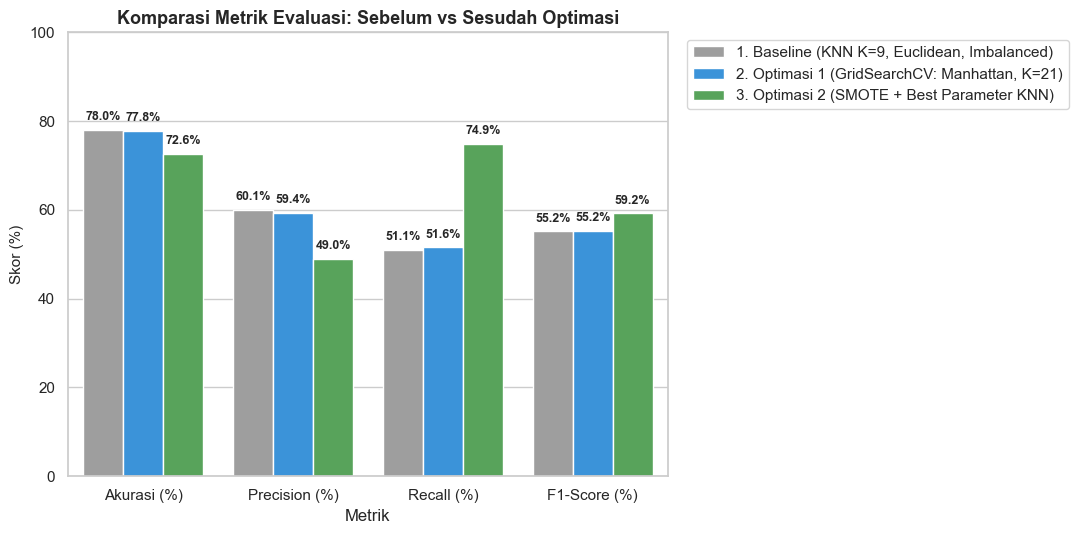

In [12]:
# Visualisasi Bar Chart komparasi
df_plot = df_komparasi.melt(id_vars='Model', var_name='Metrik', value_name='Nilai')

plt.figure(figsize=(11, 5.5))
ax = sns.barplot(data=df_plot, x='Metrik', y='Nilai', hue='Model', palette=['#9E9E9E', '#2196F3', '#4CAF50'])
plt.title('Komparasi Metrik Evaluasi: Sebelum vs Sesudah Optimasi', fontsize=13, fontweight='bold')
plt.ylabel('Skor (%)', fontsize=11)
plt.ylim(0, 100)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height:.1f}%',
                    (p.get_x() + p.get_width() / 2., height + 1.5),
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


### 5.3 Perbandingan Confusion Matrix: Baseline vs Teroptimasi (SMOTE)


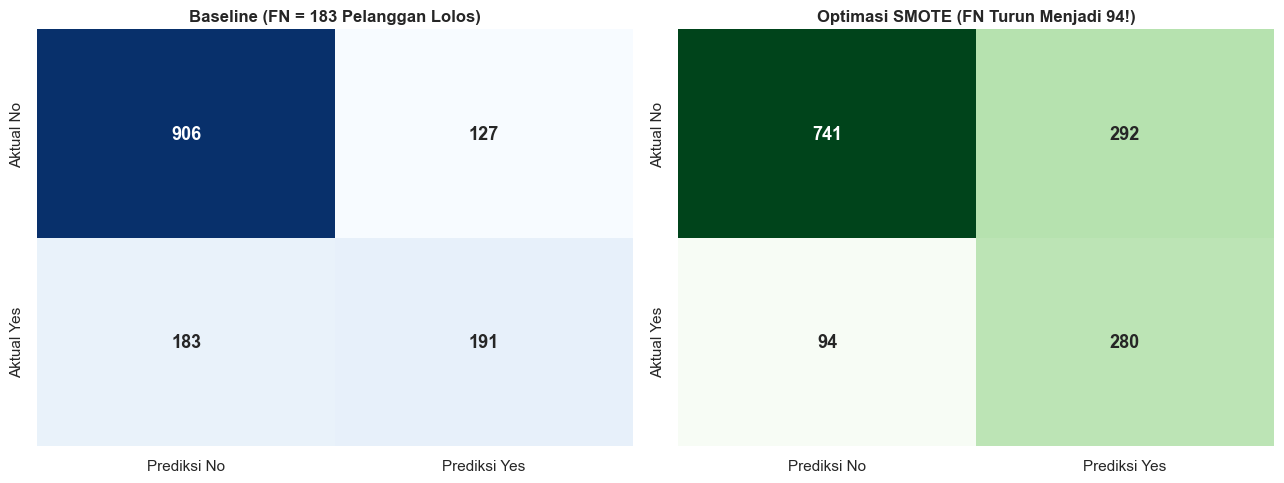

INTERPRETASI BISNIS & EVALUASI CONFUSION MATRIX:
-----------------------------------------------------------------
1. False Negative (Pelanggan churn yang gagal terdeteksi):
   Sebelum Optimasi : 183 pelanggan lolos
   Sesudah Optimasi : 94 pelanggan lolos (BERKURANG 89 pelanggan!)
2. True Positive (Pelanggan churn yang berhasil dideteksi):
   Sebelum Optimasi : 191 pelanggan
   Sesudah Optimasi : 280 pelanggan (MENINGKAT 89 pelanggan!)
3. Recall melonjak dari 51.1% menjadi 74.9%, membuktikan optimasi SMOTE sangat efektif.


In [13]:
cm_base = confusion_matrix(y_test, y_pred_base)
cm_opt2 = confusion_matrix(y_test, y_pred_opt2)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Baseline
sns.heatmap(cm_base, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Prediksi No', 'Prediksi Yes'],
            yticklabels=['Aktual No', 'Aktual Yes'],
            annot_kws={'size': 13, 'weight': 'bold'})
axes[0].set_title(f'Baseline (FN = {cm_base[1,0]} Pelanggan Lolos)', fontsize=12, fontweight='bold')

# Teroptimasi SMOTE
sns.heatmap(cm_opt2, annot=True, fmt='d', cmap='Greens', cbar=False, ax=axes[1],
            xticklabels=['Prediksi No', 'Prediksi Yes'],
            yticklabels=['Aktual No', 'Aktual Yes'],
            annot_kws={'size': 13, 'weight': 'bold'})
axes[1].set_title(f'Optimasi SMOTE (FN Turun Menjadi {cm_opt2[1,0]}!)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

fn_sebelum = cm_base[1, 0]
fn_sesudah = cm_opt2[1, 0]
tp_sebelum = cm_base[1, 1]
tp_sesudah = cm_opt2[1, 1]

print('INTERPRETASI BISNIS & EVALUASI CONFUSION MATRIX:')
print('-'*65)
print(f'1. False Negative (Pelanggan churn yang gagal terdeteksi):')
print(f'   Sebelum Optimasi : {fn_sebelum} pelanggan lolos')
print(f'   Sesudah Optimasi : {fn_sesudah} pelanggan lolos (BERKURANG {fn_sebelum - fn_sesudah} pelanggan!)')
print(f'2. True Positive (Pelanggan churn yang berhasil dideteksi):')
print(f'   Sebelum Optimasi : {tp_sebelum} pelanggan')
print(f'   Sesudah Optimasi : {tp_sesudah} pelanggan (MENINGKAT {tp_sesudah - tp_sebelum} pelanggan!)')
print(f'3. Recall melonjak dari {rec_base*100:.1f}% menjadi {rec_opt2*100:.1f}%, membuktikan optimasi SMOTE sangat efektif.')


---
## FASE 6: Deployment & Prediksi dengan Model Teroptimasi

### 6.1 Fungsi Prediksi Pelanggan Baru dengan Model Terbaik


In [14]:
def prediksi_churn_teroptimasi(data_dict):
    """
    Fungsi prediksi pelanggan baru menggunakan model KNN teroptimasi (SMOTE + Best Params).
    """
    df_input = pd.DataFrame([data_dict])
    df_norm = normalisasi_minmax(df_input[fitur_terpilih], nilai_min, nilai_max)
    
    pred = model_opt2.predict(df_norm)[0]
    prob = model_opt2.predict_proba(df_norm)[0][1]
    
    status = 'BERISIKO CHURN' if pred == 1 else 'SETIA (TIDAK CHURN)'
    rekomendasi = 'Segera tawarkan diskon/promo retensi kontrak!' if pred == 1 else 'Pertahankan kualitas layanan standar.'
    
    return {
        'Status': status,
        'Probabilitas Churn': f'{prob*100:.1f}%',
        'Rekomendasi Bisnis': rekomendasi
    }

print('Fungsi prediksi_churn_teroptimasi() siap digunakan!')


Fungsi prediksi_churn_teroptimasi() siap digunakan!


In [15]:
# Pengujian 2 profil pelanggan berbeda:
pelanggan_baru = {f: 0 for f in fitur_terpilih}
pelanggan_baru.update({
    'tenure': 3,
    'MonthlyCharges': 89.5,
    'TotalCharges': 268.5,
    'InternetService_Fiber optic': 1,
    'PaymentMethod_Electronic check': 1,
    'PaperlessBilling_Yes': 1,
    'Contract_Two year': 0,
    'Contract_One year': 0
})

hasil_uji = prediksi_churn_teroptimasi(pelanggan_baru)
print('HASIL PREDIKSI PELANGGAN BARU (MODEL TEROPTIMASI):')
print('='*55)
for k, v in hasil_uji.items():
    print(f'{k:20s}: {v}')


HASIL PREDIKSI PELANGGAN BARU (MODEL TEROPTIMASI):
Status              : BERISIKO CHURN
Probabilitas Churn  : 88.9%
Rekomendasi Bisnis  : Segera tawarkan diskon/promo retensi kontrak!
